Name: Sana Raza

Labpartner(s)

In [1]:
#import statements go here
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
import numpy as np

# Class 9.2

For the lab you will integrate zotero into word, google docs, and optionally LaTeX.

Reminder your final project proposal is due Sunday. On Monday you will pitch your final project proposal to the class


**W.1** Make a map of the Gulf Coast in Cartopy, and figure our how to add rivers and state boundaries. Add a marker for Baton Rouge.

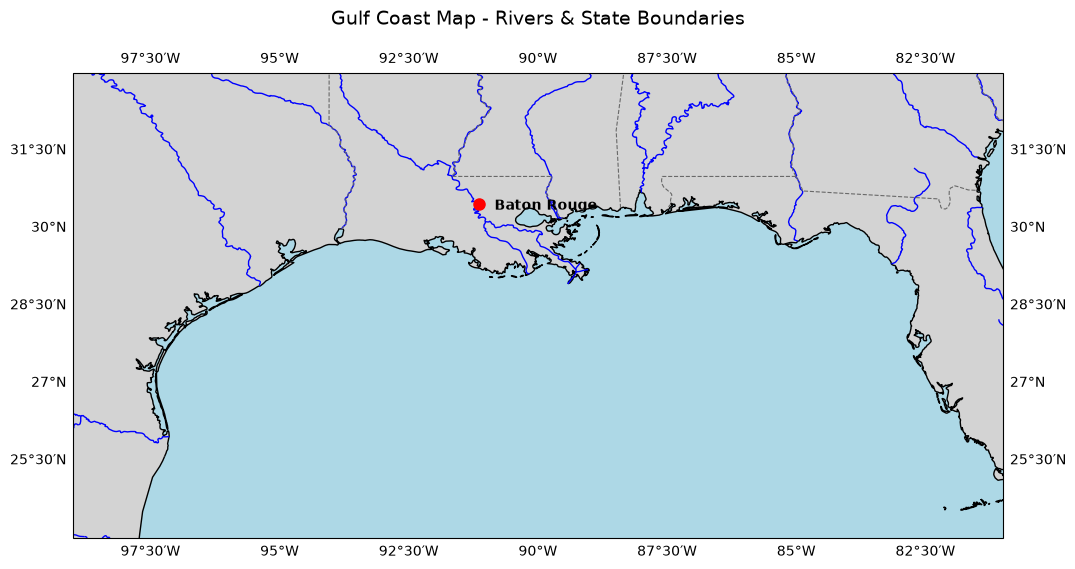

In [2]:
# 1. Setting up the figure and map projection (PlateCarree is standard for lat/lon data)
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# 2. Zooming into the Gulf Coast region [xmin, xmax, ymin, ymax]
ax.set_extent([-99, -81, 24, 33], crs=ccrs.PlateCarree())

# 3. Adding base layers (Land, Ocean, and Coastlines)
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='lightblue')
ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=1)

# 4. Adding Rivers (using standard scaling resolution)
ax.add_feature(cfeature.RIVERS, edgecolor='blue', linewidth=1)

# 5. Adding State Boundaries (US States feature)
# 50m resolution provides a good balance of detail for a regional scale
states_provinces = cfeature.NaturalEarthFeature(
    category='cultural',
    name='admin_1_states_provinces_lines',
    scale='50m',
    facecolor='none'
)
ax.add_feature(states_provinces, edgecolor='dimgray', linestyle='--', linewidth=0.8)

# 6. Adding a marker for Baton Rouge (30.4583° N, 91.1403° W)
# Longitude is negative for West
br_lon, br_lat = -91.1403, 30.4583

# Specifying 'transform=ccrs.PlateCarree()' so Cartopy knows your inputs are lat/lon
ax.plot(br_lon, br_lat, marker='o', color='red', markersize=8, transform=ccrs.PlateCarree(), label='Baton Rouge')
ax.text(br_lon + 0.3, br_lat - 0.1, 'Baton Rouge', transform=ccrs.PlateCarree(), fontsize=10, weight='bold')

# 7.Layout adjustments
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, color='none')
plt.title('Gulf Coast Map - Rivers & State Boundaries', fontsize=14, pad=20)

plt.show()

**W.2** Do some more work on the Chipotle data from Monday

In [3]:
# reading the dataset

chipo = pd.read_csv("https://raw.githubusercontent.com/justmarkham/DAT8/master/data/chipotle.tsv", sep="\t")
chipo.head()

,order_id,quantity,item_name,choice_description,item_price
0,1,1,Chips and Fresh Tomato Salsa,NaN,$2.39
1,1,1,Izze,[Clementine],$3.39
2,1,1,Nantucket Nectar,[Apple],$3.39
3,1,1,Chips and Tomatillo-Green Chili Salsa,NaN,$2.39
4,2,2,Chicken Bowl,"[Tomatillo-Red Chili Salsa (Hot), [Black Beans...",$16.98


In [4]:
# converting prices from text ("$2.39 ") to numbers (2.39)
chipo["item_price"] = chipo["item_price"].str.replace("$", "", regex=False).astype(float)
chipo["product_price"] = chipo["item_price"] / chipo["quantity"]

In [5]:
# finding the items that are ordered the most
top_items = chipo.groupby("item_name")["quantity"].sum().sort_values(ascending=False)
top_items.head(5)

# the most ordered item is chicken bowl

item_name
Chicken Bowl           761
Chicken Burrito        591
Chips and Guacamole    506
Steak Burrito          386
Canned Soft Drink      351
Name: quantity, dtype: int64

In [6]:
# how much is the typical order cost
order_totals = chipo.groupby("order_id")["item_price"].sum()
print("Average order: $", round(order_totals.mean(), 2))
print("Most expensive order: $", order_totals.max())

Average order: $ 18.81
Most expensive order: $ 205.25


In [7]:
chipo.groupby("item_name")["product_price"].mean().sort_values(ascending=False).head(5)

# the most expensive item is Carnitas Salad Bowl 

item_name
Carnitas Salad Bowl    11.056667
Steak Salad Bowl       11.027931
Barbacoa Salad Bowl    10.640000
Carnitas Bowl          10.315588
Steak Bowl             10.232559
Name: product_price, dtype: float64

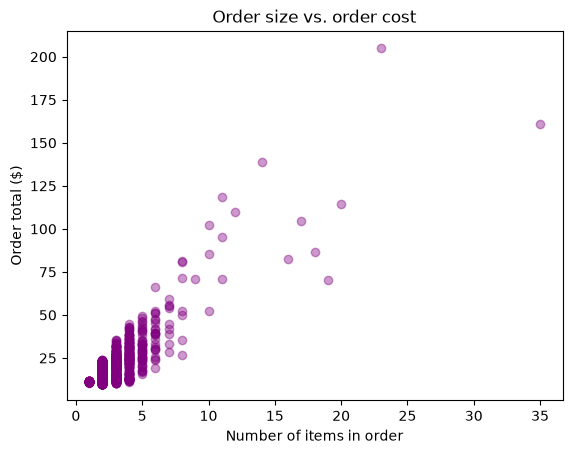

In [8]:
# do bigger orders cost more?

items_per_order = chipo.groupby("order_id")["quantity"].sum()
plt.scatter(items_per_order, order_totals, alpha=0.4, color="purple")
plt.xlabel("Number of items in order")
plt.ylabel("Order total ($)")
plt.title("Order size vs. order cost")
plt.show()

# Lecture 9.2

### Agenda:

- Questions
- Intro to Zotero

### Questions

# Lab 9.2

**E.0** Complete the previous labs if you are behind.

**E.1** Install Zotero and the plugins for your web browser (Chrome or Firefox suggested), Word, and Google docs. Use Zotero to grab a 2-3 citations from the web (e.g., from a scientific journal article web page), then cite them in both Word and Google docs in a sentance or two, then add a Bibliography using zotero.

In Moodle, turn in your word document, a screenshot of your google doc, and a screenshot of your zotero library.

Added

**E.3** Complete your final project proposal and submit it in Moodle

**E.4** Prepare a 5 min presentation of your project proposal, including a brief introduction, your research plan, the programming methods you are planning to use, your preliminary results/plots, and your timeline for completion. ​You will present this in class next Monday.

A good target length is 1 slide per minute.

Upload your talk here: https://lsu.box.com/s/jc4x0p5mu7u1tst38m98i0t1e35z2mfl


**B.1** Bonus! Integrate zotero and overleaf. Note to have the zotero plugin for overleaf you have to pay them. However, you can export a .bib style bibliography for LaTeX and load it into overleaf. If you are extra, go for it! Submit a pdf of your LaTeX document with citations and bibliography, and a screenshot of your .bib file

Added on Moodle. 

**Notes** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

### Cartopy (maps)
- `ccrs.PlateCarree()` – projection for latitude and longitude.
- `ax.set_extent([lon_min, lon_max, lat_min, lat_max])` - helpful for zooming in a region
- `ax.add_feature(cfeature.COASTLINE)`, `cfeature.RIVERS` -- for adding layers
- `transform=ccrs.PlateCarree()` – used to plot a point

### Plotting
- `plt.scatter(x, y, color="purple", alpha=0.4)` – alpha is used to make see-through dots